# **Transcriptomic Changes Associated with Adipogenic Differentiation in Mouse Embryonic Stem Cells**

**Reproducible exploratory reanalysis of publicly available RNA-seq data**

## **Research question**

How do gene-expression profiles differ between non-differentiating (Neg) and differentiating (Pos) mouse embryonic stem cell samples, and which biological annotations are associated with the observed patterns?

## **Project summary**

This notebook presents a computational reanalysis of a publicly available variance-stabilized (VST) gene-expression matrix containing three Neg and three Pos samples. The workflow combines data-quality assessment, principal component analysis (PCA), exploratory differential-expression screening, heatmap visualization, direction-specific Gene Ontology (GO) over-representation analysis, selected gene-set enrichment analysis (GSEA), and candidate-gene expression summaries.

Interpretive boundary: The input consists of processed VST expression values, not raw counts. Welch’s two-sample t-tests on these values provide an exploratory screen and are not equivalent to count-based differential-expression modelling with DESeq2 or edgeR. With only three samples per condition, inferential findings require cautious interpretation. Expression differences and enrichment results identify associations and hypotheses for further investigation; they do not establish causal mechanisms.

## **1. Scientific background and connection to the reference study**

The reference study investigated transcriptional dynamics and candidate regulators associated with adipogenesis in mouse embryonic stem cells. This project is a computational reanalysis of an available processed expression matrix, not a reproduction of every analysis in the paper and not an independent experimental study.

The workflow asks whether the six profiles show condition-associated structure, identifies rows with exploratory expression differences, and tests whether selected gene lists are over-represented for functional annotations. Enrichment describes associations among annotations; it does not demonstrate that a process is activated, suppressed, or causally responsible for differentiation.

**Reference:** Sultana et al. (2024). “Transcriptional Dynamics and Key Regulators of Adipogenesis in Mouse Embryonic Stem Cells: Insights from Robust Rank Aggregation Analysis.” *International Journal of Molecular Sciences*, 25(17), 9154. [Article](https://pmc.ncbi.nlm.nih.gov/articles/PMC11395306/) | [Supplementary material](https://www.mdpi.com/article/10.3390/ijms25179154/s1?download=1)


## **2. Dataset provenance, samples, and limitations**

- **BioProject:** PRJNA1126392
- **SRA study:** SRP515101
- **Repository:** [Al-Sayegh lab bioinformatics repository](https://github.com/mxa1429/msc-bioinformatics-mohamed-alsayegh)
- **Expression matrix:** [vst_matrix_genes.csv](https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/refs/heads/main/Codes/vst_matrix_genes.csv)
- **Expected columns:** `gene.names`, `Neg_1`, `Neg_2`, `Neg_3`, `Pos_1`, `Pos_2`, `Pos_3`
- **Contrast:** Pos minus Neg; positive differences indicate higher mean VST expression in Pos.

The matrix is a processed VST matrix, not raw counts. The analysis cannot reconstruct a valid count-based model from VST values. The small sample size limits estimates of biological variability, and gene symbols may not be unique identifiers. Data source and software versions are recorded below when execution succeeds.


## **3. Reproducible setup and data loading**

The loader first tries the public repository URL and then checks for a local `vst_matrix_genes.csv` file (useful in Colab after uploading the data). It fails clearly if neither source is available; it does not substitute example or fabricated data.


In [1]:
%pip install -q gseapy
print('GSEApy dependency is ready. If installation reports an error, check the runtime internet connection.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 10.3 MB/s eta 0:00:00
GSEApy dependency is ready. If installation reports an error, check the runtime internet connection.


In [2]:
from pathlib import Path
import platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, hypergeom
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

SEED = 42
ALPHA = 0.05
SAMPLE_COLS = ["Neg_1", "Neg_2", "Neg_3", "Pos_1", "Pos_2", "Pos_3"]
NEG_COLS = SAMPLE_COLS[:3]
POS_COLS = SAMPLE_COLS[3:]
GENE_COL = "gene.names"
DATA_URL = "https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/refs/heads/main/Codes/vst_matrix_genes.csv"

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.titleweight": "bold", "axes.labelsize": 10})

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Data source:", DATA_URL)

try:
    df_raw = pd.read_csv(DATA_URL)
    data_source_used = DATA_URL
except Exception as remote_error:
    local_candidates = [Path("vst_matrix_genes.csv"), Path("/content/vst_matrix_genes.csv")]
    local_path = next((p for p in local_candidates if p.exists()), None)
    if local_path is None:
        raise RuntimeError(
            "Could not retrieve the expression matrix from the repository and no local "
            "vst_matrix_genes.csv was found. Check internet access or place the original "
            "CSV beside this notebook / upload it in Colab. No results have been fabricated."
        ) from remote_error
    df_raw = pd.read_csv(local_path)
    data_source_used = str(local_path.resolve())

required = [GENE_COL, *SAMPLE_COLS]
missing_columns = [c for c in required if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from expression matrix: {missing_columns}")

# Keep a pristine copy for traceability; normalize labels only in a separate analysis column.
df = df_raw[required].copy()
for col in SAMPLE_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["gene_label_original"] = df[GENE_COL]
df["gene_symbol"] = df[GENE_COL].astype("string").str.strip()
df.loc[df["gene_symbol"].isin(["", "NA", "N/A", "nan", "None"]), "gene_symbol"] = pd.NA

print(f"Loaded source: {data_source_used}")
print(f"Matrix dimensions (rows × columns): {df_raw.shape[0]:,} × {df_raw.shape[1]:,}")
display(df_raw.head())


Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
Data source: https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/refs/heads/main/Codes/vst_matrix_genes.csv
Loaded source: https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/refs/heads/main/Codes/vst_matrix_genes.csv
Matrix dimensions (rows × columns): 46,603 × 7


,gene.names,Neg_1,Neg_2,Neg_3,Pos_1,Pos_2,Pos_3
0,Gnai3,12.722687,12.761691,12.873918,13.258710,13.282136,13.002556
1,Pbsn,3.872154,3.872154,3.872154,3.872154,3.872154,3.872154
2,Cdc45,8.090108,8.071735,8.020891,8.801457,8.829139,8.588195
3,H19,16.510410,16.656625,16.502528,14.908266,15.428432,16.144464
4,Scml2,7.285921,7.205858,7.069953,6.772985,6.812367,6.930409


## **4. Data validation and gene-label quality assessment**

The matrix rows are the primary units for the expression-screening step. Gene symbols are normalized only by trimming surrounding whitespace and marking common empty/missing strings as missing. Duplicate symbols are **not silently collapsed**: the original row-level screen is retained, while gene-set analyses use unique, non-missing symbols because enrichment libraries are symbol-based. Where multiple rows map to one symbol, the direction-specific selection includes that symbol once.

This distinction matters: duplicated symbols can inflate row-level counts and can create multiple statistical tests for the same displayed gene label. They may also complicate mapping to GO terms. No arbitrary averaging or “first row wins” rule is applied to the source matrix.


In [3]:
n_rows = len(df)
n_missing_labels = int(df["gene_symbol"].isna().sum())
label_counts = df.loc[df["gene_symbol"].notna(), "gene_symbol"].value_counts()
duplicate_labels = label_counts[label_counts > 1]
duplicate_rows = int(label_counts[label_counts > 1].sum())
unique_symbols = int(df["gene_symbol"].nunique(dropna=True))
missing_expr = df[SAMPLE_COLS].isna().sum()
nonfinite_expr = (~np.isfinite(df[SAMPLE_COLS].to_numpy(dtype=float))).sum()

qc_summary = pd.DataFrame({"Metric": [
    "Expression matrix rows", "Non-missing unique normalized gene symbols",
    "Rows belonging to duplicated symbols", "Symbols occurring more than once",
    "Rows with missing gene labels", "Missing expression cells", "Non-finite expression cells"
], "Value": [n_rows, unique_symbols, duplicate_rows, len(duplicate_labels), n_missing_labels,
             int(missing_expr.sum()), int(nonfinite_expr)]})
display(qc_summary)
print("Missing expression values by sample:")
display(missing_expr.rename("missing_values").to_frame())
print("Most frequent duplicated labels:")
display(duplicate_labels.head(15).rename("row_count").to_frame())

if df[SAMPLE_COLS].isna().all(axis=1).any():
    print("Warning: rows with all six expression values missing will be excluded from numeric analyses.")
if nonfinite_expr:
    print("Warning: non-finite expression values detected; affected rows are excluded from analyses requiring complete values.")


,Metric,Value
0,Expression matrix rows,46603
1,Non-missing unique normalized gene symbols,46475
2,Rows belonging to duplicated symbols,222
3,Symbols occurring more than once,94
4,Rows with missing gene labels,0
5,Missing expression cells,0
6,Non-finite expression cells,0


Missing expression values by sample:


,missing_values
Neg_1,0
Neg_2,0
Neg_3,0
Pos_1,0
Pos_2,0
Pos_3,0


Most frequent duplicated labels:


,row_count
gene_symbol,
mmu-mir-669a-4,9
Flg,8
SCARNA15,5
SCARNA4,5
ACEA_U3,5
SNORA43,4
SNORA17,4
Il11ra2,3
Gm20796,3


## **5. Exploratory expression distributions**

This section checks whether sample-level VST distributions are broadly comparable and flags missingness before multivariate analysis. Distribution plots are descriptive and do not test whether samples are biologically equivalent.


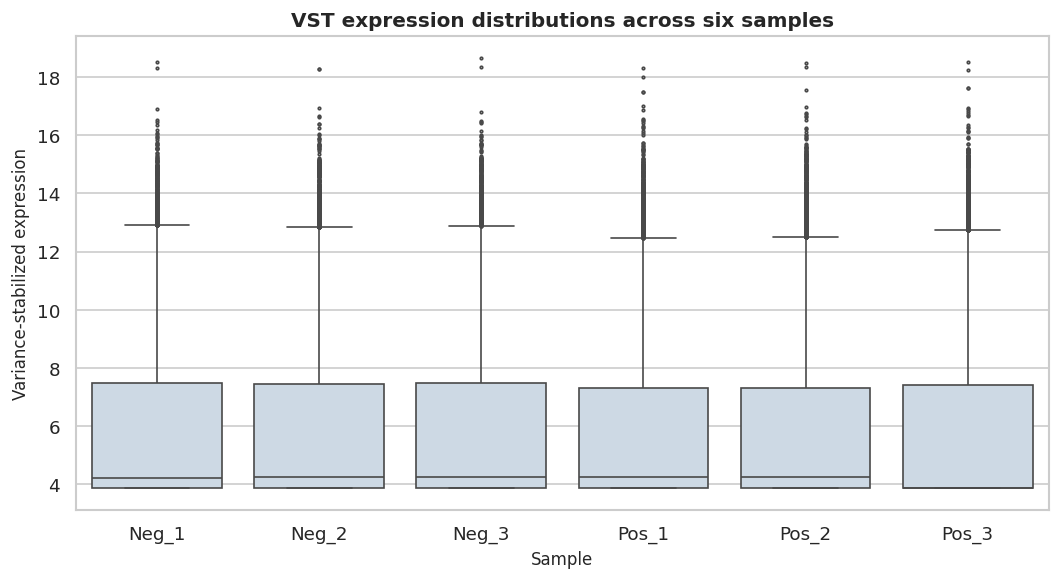

,count,mean,std,min,25%,50%,75%,max
Neg_1,46603.0,5.770,2.720,3.872,3.872,4.224,7.484,18.535
Neg_2,46603.0,5.766,2.738,3.872,3.872,4.242,7.458,18.295
Neg_3,46603.0,5.769,2.718,3.872,3.872,4.237,7.481,18.668
Pos_1,46603.0,5.734,2.714,3.872,3.872,4.253,7.315,18.308
Pos_2,46603.0,5.731,2.726,3.872,3.872,4.238,7.324,18.494
Pos_3,46603.0,5.742,2.740,3.872,3.872,3.872,7.415,18.529


In [4]:
valid_expr = np.isfinite(df[SAMPLE_COLS].to_numpy(dtype=float)).all(axis=1)
expr_complete = df.loc[valid_expr, SAMPLE_COLS].astype(float)
if expr_complete.empty:
    raise ValueError("No rows with complete finite values across all six samples are available.")

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=expr_complete, ax=ax, color="#c9d9e8", fliersize=1.5)
ax.set(title="VST expression distributions across six samples", xlabel="Sample", ylabel="Variance-stabilized expression")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout(); plt.show()
display(expr_complete.describe().T.round(3))


## **6. Principal component analysis (PCA)**

PCA is performed on samples as observations and genes as features. Features are centered and scaled before PCA so that high-variance genes do not automatically dominate solely because of their scale. PCA is exploratory: separation can reflect condition-associated biology as well as technical or other sample differences. The small sample count means each point is influential.


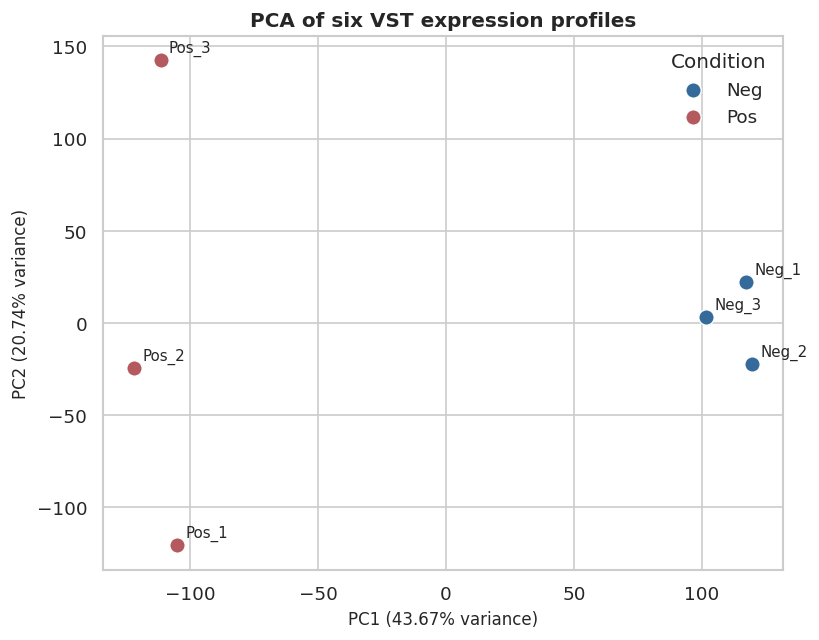

PC1 variance explained: 43.67%
PC2 variance explained: 20.74%


,Sample,Condition,PC1,PC2
0,Neg_1,Neg,117.2834,22.2121
1,Neg_2,Neg,119.5297,-22.5233
2,Neg_3,Neg,101.6179,3.0249
3,Pos_1,Pos,-105.0594,-120.6280
4,Pos_2,Pos,-121.8741,-24.4534
5,Pos_3,Pos,-111.4975,142.3676


In [5]:
# PCA requires complete values for the genes used. The matrix is samples × genes.
pca_input = expr_complete.T
scaler = StandardScaler(with_mean=True, with_std=True)
X_scaled = scaler.fit_transform(pca_input)
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)
meta = pd.DataFrame({"Sample": SAMPLE_COLS, "Condition": ["Neg"]*3 + ["Pos"]*3,
                     "PC1": coords[:, 0], "PC2": coords[:, 1]})
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = {"Neg": "#356a9a", "Pos": "#b45a5f"}
for condition, group in meta.groupby("Condition", sort=False):
    ax.scatter(group.PC1, group.PC2, label=condition, s=85, color=colors[condition], edgecolor="white", linewidth=0.8)
    for _, row in group.iterrows():
        ax.annotate(row.Sample, (row.PC1, row.PC2), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set(title="PCA of six VST expression profiles", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)")
ax.legend(title="Condition", frameon=False)
fig.tight_layout(); plt.show()
print(f"PC1 variance explained: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2 variance explained: {pca.explained_variance_ratio_[1]*100:.2f}%")
display(meta.round(4))


## **7. Exploratory differential-expression screening**

For each matrix row with at least two finite observations in each condition, Welch's two-sample t-test compares Neg and Pos VST values. The contrast is defined as **Pos mean − Neg mean**. Benjamini–Hochberg adjustment is applied across the full matrix-row family (all 46,603 rows). Rows without a valid Welch-test p-value retain a missing raw p-value but contribute p = 1 to the adjustment family; this keeps the declared family size explicit without pretending an undefined test was observed. This is a transparent exploratory screen, not a count-based RNA-seq differential-expression model. Constant rows, missing observations, and numerical edge cases are handled explicitly.


In [6]:
from scipy.stats import ttest_ind

results = df[[GENE_COL, "gene_symbol", *SAMPLE_COLS]].copy()
results["Neg_mean"] = results[NEG_COLS].mean(axis=1, skipna=True)
results["Pos_mean"] = results[POS_COLS].mean(axis=1, skipna=True)
results["difference"] = results["Pos_mean"] - results["Neg_mean"]
results["p_value"] = np.nan

neg = results[NEG_COLS].to_numpy(dtype=float)
pos = results[POS_COLS].to_numpy(dtype=float)
for i in range(len(results)):
    a, b = neg[i], pos[i]
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) >= 2 and len(b) >= 2:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            test = ttest_ind(a, b, equal_var=False, nan_policy="omit")
        if np.isfinite(test.pvalue):
            results.loc[results.index[i], "p_value"] = float(test.pvalue)

valid_p = results["p_value"].notna() & np.isfinite(results["p_value"])
# Preserve missing raw p-values, but use p=1 for undefined tests in the full
# 46,603-row multiple-testing family, matching the stated analysis protocol.
p_for_bh = results["p_value"].where(valid_p, 1.0).to_numpy(dtype=float)
results["adjusted_p"] = multipletests(p_for_bh, method="fdr_bh")[1]
results["significant"] = results["adjusted_p"] < ALPHA
results["direction"] = np.select(
    [results["significant"] & (results["difference"] > 0), results["significant"] & (results["difference"] < 0)],
    ["Higher in Pos", "Lower in Pos"], default="Not significant / unresolved")

n_tested = int(valid_p.sum())
sig_rows = results.loc[results["significant"]].copy()
print(f"Matrix rows: {len(results):,}")
print(f"Rows with valid tests: {n_tested:,}")
print(f"Rows with BH-adjusted p < {ALPHA}: {len(sig_rows):,}")
print(f"Significant rows higher in Pos: {(sig_rows['difference'] > 0).sum():,}")
print(f"Significant rows lower in Pos: {(sig_rows['difference'] < 0).sum():,}")
print("Note: these are matrix-row counts; duplicate symbols can occur more than once.")

ranked_results = results.sort_values(["adjusted_p", "p_value"], na_position="last")
display(ranked_results[[GENE_COL, "Neg_mean", "Pos_mean", "difference", "p_value", "adjusted_p", "direction"]].head(20).round(6))


Matrix rows: 46,603
Rows with valid tests: 29,270
Rows with BH-adjusted p < 0.05: 1,089
Significant rows higher in Pos: 344
Significant rows lower in Pos: 745
Note: these are matrix-row counts; duplicate symbols can occur more than once.


,gene.names,Neg_mean,Pos_mean,difference,p_value,adjusted_p,direction
7255,Alb,12.592416,4.297210,-8.295206,0.000000,0.002218,Lower in Pos
10146,Krt20,10.364329,6.003149,-4.361181,0.000000,0.006227,Lower in Pos
7256,Afm,9.116314,4.574384,-4.541930,0.000000,0.006227,Lower in Pos
17102,Samd5,8.715053,6.449462,-2.265591,0.000001,0.006227,Lower in Pos
949,Upk3bl,10.101157,5.506050,-4.595107,0.000001,0.008477,Lower in Pos
2539,Myl7,8.974589,10.592975,1.618386,0.000002,0.008477,Higher in Pos
3966,Ildr1,9.428065,5.348183,-4.079881,0.000002,0.008477,Lower in Pos
7236,Cds1,9.481665,6.798796,-2.682869,0.000002,0.008477,Lower in Pos
6264,Slc2a2,10.920020,4.766279,-6.153742,0.000002,0.008477,Lower in Pos
9355,Adamts15,10.636169,11.958270,1.322101,0.000002,0.008477,Higher in Pos


### **Volcano plot**

The x-axis shows the Pos − Neg difference in mean VST expression, not a log fold change. The y-axis is −log10 of the raw p-value for visual screening; significance classification is based on the BH-adjusted p-value. Zero or missing p-values are handled for plotting without changing the stored statistics.


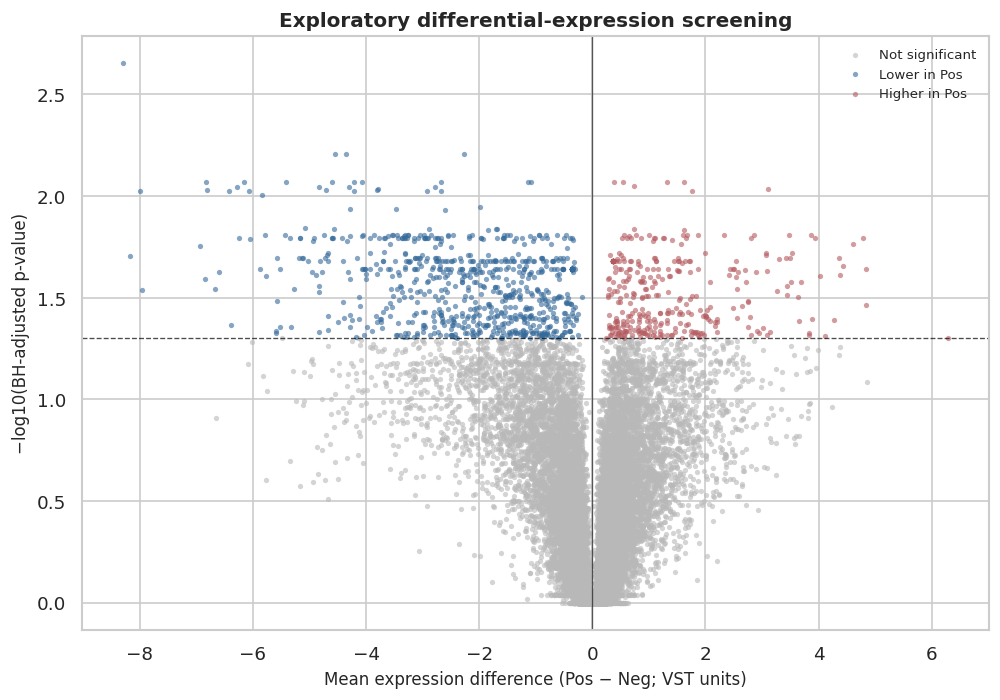

In [7]:

# Volcano plot using BH-adjusted p-values

plot_df = results.loc[
    results["adjusted_p"].notna()
    & np.isfinite(results["adjusted_p"])
].copy()

plot_df["neg_log10_adjusted_p"] = -np.log10(
    plot_df["adjusted_p"].clip(lower=np.finfo(float).tiny)
)

plot_df["plot_group"] = np.where(
    plot_df["adjusted_p"] < ALPHA,
    plot_df["direction"],
    "Not significant"
)

palette = {
    "Higher in Pos": "#b45a5f",
    "Lower in Pos": "#356a9a",
    "Not significant": "#b8b8b8",
    "Not significant / unresolved": "#b8b8b8",
}

fig, ax = plt.subplots(figsize=(8.5, 6))

for group in [
    "Not significant",
    "Lower in Pos",
    "Higher in Pos",
    "Not significant / unresolved",
]:
    sub = plot_df[plot_df["plot_group"] == group]
    if not sub.empty:
        ax.scatter(
            sub["difference"],
            sub["neg_log10_adjusted_p"],
            s=10,
            alpha=0.6,
            label=group,
            c=palette[group],
            linewidths=0,
        )

ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
ax.axhline(-np.log10(ALPHA), color="black", linestyle="--",
           linewidth=0.8, alpha=0.7)

ax.set(
    title="Exploratory differential-expression screening",
    xlabel="Mean expression difference (Pos − Neg; VST units)",
    ylabel="−log10(BH-adjusted p-value)",
)

ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()



## **8. Expression heatmap for selected genes**

The heatmap uses a prespecified panel of candidate adipogenic, extracellular-matrix, and differentiation-associated symbols, plus the most significant unique symbols where available. Duplicate symbol rows are not arbitrarily averaged: for visualization only, if a symbol has multiple matrix rows, the row with the smallest adjusted p-value is selected when available, otherwise the first source row is used. This rule is explicit and applies only to the display, not to the row-level statistical table. Values are standardized within each gene across the six samples.


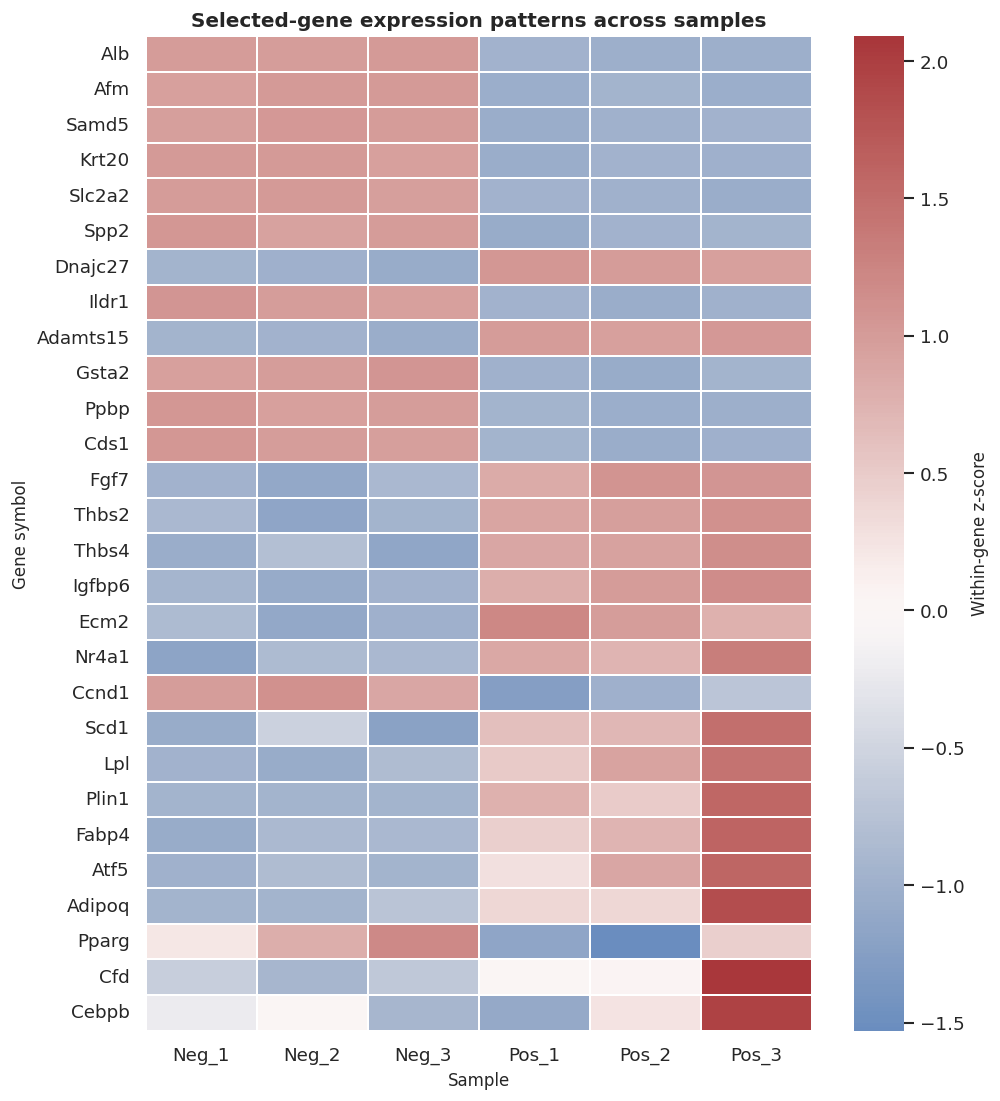

Unique gene symbols plotted: 28


In [8]:
candidate_panel = ["PPARG", "CEBPB", "FABP4", "ATF5", "CCND1", "NR4A1", "Lpl", "Plin1", "Adipoq", "Cfd", "Scd1", "Thbs2", "Thbs4", "Ecm2", "Igfbp6", "Fgf7", "Krt20", "Slc2a2", "Spp2"]
# Preserve the actual spelling found in the matrix by matching case-insensitively.
lookup = {str(s).casefold(): str(s) for s in results["gene_symbol"].dropna().unique()}
requested = [lookup[g.casefold()] for g in candidate_panel if g.casefold() in lookup]
top_symbols = (results.loc[results["adjusted_p"].notna()].sort_values("adjusted_p")["gene_symbol"].dropna().drop_duplicates().head(12).tolist())
selected_symbols = list(dict.fromkeys(requested + top_symbols))
heat_source = results[results["gene_symbol"].isin(selected_symbols)].copy()
heat_source["_rank_p"] = heat_source["adjusted_p"].fillna(np.inf)
heat_source = heat_source.sort_values("_rank_p").drop_duplicates("gene_symbol", keep="first")
heat_mat = heat_source.set_index("gene_symbol")[SAMPLE_COLS].astype(float)
heat_mat = heat_mat.dropna(axis=0, how="any")
if not heat_mat.empty:
    sd = heat_mat.std(axis=1, ddof=0).replace(0, np.nan)
    heat_z = heat_mat.sub(heat_mat.mean(axis=1), axis=0).div(sd, axis=0).dropna(axis=0, how="any")
    if not heat_z.empty:
        fig_h = max(5, 0.28 * len(heat_z) + 1.5)
        fig, ax = plt.subplots(figsize=(8.5, fig_h))
        sns.heatmap(heat_z, cmap="vlag", center=0, linewidths=0.25, linecolor="white", cbar_kws={"label": "Within-gene z-score"}, ax=ax)
        ax.set(title="Selected-gene expression patterns across samples", xlabel="Sample", ylabel="Gene symbol")
        fig.tight_layout(); plt.show()
        print(f"Unique gene symbols plotted: {len(heat_z)}")
    else:
        print("Heatmap skipped: selected genes have no non-constant complete expression profiles.")
else:
    print("Heatmap skipped: none of the selected symbols were found with complete expression values.")


## **9. Gene Ontology (GO) Biological Process over-representation**

GO analysis requires a gene-set library and a defensible universe. The preferred universe here is the set of unique, non-missing gene symbols that were eligible for row-level testing and could therefore have been selected. Because the input is a symbol-labelled processed matrix, this universe is still subject to annotation coverage and symbol-mapping limitations.

This section attempts to obtain the **GO Biological Process 2023** library via GSEApy. It then calculates a one-sided hypergeometric over-representation p-value using the tested-symbol universe and applies BH correction across all library terms tested for each direction. If the library cannot be retrieved or GSEApy is unavailable, the notebook reports the limitation and does not invent enrichment results.


In [9]:
# A row is eligible for symbol-level universe membership if it had a valid test.
# Normalize symbols case-insensitively for annotation matching (e.g., Krt20 vs KRT20),
# while retaining dataset spellings for the reported overlap genes.
eligible_symbols = set(results.loc[valid_p, "gene_symbol"].dropna().astype(str))
up_symbols = set(results.loc[(results["adjusted_p"] < ALPHA) & (results["difference"] > 0), "gene_symbol"].dropna().astype(str))
down_symbols = set(results.loc[(results["adjusted_p"] < ALPHA) & (results["difference"] < 0), "gene_symbol"].dropna().astype(str))

def _symbol_key(value):
    return str(value).strip().casefold()

# One canonical dataset symbol per normalized key. Duplicate case variants are resolved
# deterministically; row-level differential testing above remains unchanged.
canonical_by_key = {}
for symbol in sorted(eligible_symbols, key=lambda x: (x.casefold(), x)):
    canonical_by_key.setdefault(_symbol_key(symbol), symbol)
universe_keys = set(canonical_by_key)
up_keys = {_symbol_key(x) for x in up_symbols} & universe_keys
down_keys = {_symbol_key(x) for x in down_symbols} & universe_keys
print(f"Unique tested symbols in universe: {len(universe_keys):,}")
print(f"Unique higher-in-Pos symbols: {len(up_keys):,}")
print(f"Unique lower-in-Pos symbols: {len(down_keys):,}")

go_results = {}
try:
    import gseapy as gp
    print("GSEApy version:", getattr(gp, "__version__", "unknown"))
    go_library = gp.get_library(name="GO_Biological_Process_2023", organism="Mouse")
    if not go_library:
        raise RuntimeError("GO library returned no gene sets")
    # Match GO library symbols to the tested universe case-insensitively.
    term_rows = []
    for term, genes in go_library.items():
        term_keys = {_symbol_key(g) for g in genes} & universe_keys
        if term_keys:
            term_rows.append((term, term_keys))
    M = len(universe_keys)
    if M == 0:
        raise RuntimeError("No eligible gene symbols in enrichment universe")
    for direction, query_keys in [("Higher in Pos", up_keys), ("Lower in Pos", down_keys)]:
        rows = []
        for term, term_keys in term_rows:
            overlap_keys = query_keys & term_keys
            # Include zero-overlap terms with p=1 so BH correction spans all mapped terms.
            pval = float(hypergeom.sf(len(overlap_keys)-1, M, len(term_keys), len(query_keys))) if overlap_keys else 1.0
            overlap_symbols = sorted(canonical_by_key[k] for k in overlap_keys)
            rows.append({"Term": term, "Overlap_count": len(overlap_keys), "Term_size_in_universe": len(term_keys),
                         "Query_size": len(query_keys), "Universe_size": M, "P-value": pval,
                         "Genes": "; ".join(overlap_symbols)})
        out = pd.DataFrame(rows)
        if not out.empty:
            out["Adjusted P-value"] = multipletests(out["P-value"], method="fdr_bh")[1]
            out = out.sort_values(["Adjusted P-value", "P-value", "Term"], kind="mergesort").reset_index(drop=True)
        go_results[direction] = out
        n_sig = int((out["Adjusted P-value"] < ALPHA).sum()) if not out.empty else 0
        print(f"{direction}: {n_sig} terms with BH-adjusted p < {ALPHA} across {len(term_rows):,} mapped library terms")
        display(out.head(15).round(6) if not out.empty else out)
except Exception as exc:
    print("GO enrichment was not completed; no enrichment values are reported.")
    print(f"Reason: {type(exc).__name__}: {exc}")
    print("Check package availability and internet access, then rerun this section. The notebook does not substitute saved or expected results.")


Unique tested symbols in universe: 29,236
Unique higher-in-Pos symbols: 344
Unique lower-in-Pos symbols: 745
GSEApy version: 1.3.1
Higher in Pos: 6 terms with BH-adjusted p < 0.05 across 5,404 mapped library terms


,Term,Overlap_count,Term_size_in_universe,Query_size,Universe_size,P-value,Genes,Adjusted P-value
0,Neuron Migration (GO:0001764),7,49,344,29236,0.000002,Astn1; Astn2; Cep85l; Fgfr1; Nell1; Nrcam; Ntrk2,0.003112
1,Nervous System Development (GO:0007399),18,408,344,29236,0.000002,Apba1; Apba2; Cdk5rap2; Dclk1; Dpysl4; Fgf5; G...,0.003112
2,Generation Of Neurons (GO:0048699),11,157,344,29236,0.000003,Astn1; Astn2; Cep85l; En1; Fgfr1; Irx1; Nell1;...,0.003112
3,Regulation Of Neuron Differentiation (GO:0045664),8,75,344,29236,0.000003,Alk; Cdk5rap2; Dkk1; Fgfr1; Gprc5b; Hoxd3; Nrc...,0.003112
4,Positive Regulation Of Cell Differentiation (G...,14,260,344,29236,0.000003,Fgfr1; Gdnf; Gja1; Glipr2; Gprc5b; Hoxd3; Lama...,0.003112
5,Transepithelial Transport (GO:0070633),4,17,344,29236,0.000040,Best1; Slc1a2; Slc1a3; Slc26a6,0.035771
6,L-alpha-amino Acid Transmembrane Transport (GO...,5,38,344,29236,0.000080,Slc1a2; Slc1a3; Slc25a18; Slc43a1; Slc7a5,0.058469
7,Commissural Neuron Axon Guidance (GO:0071679),3,8,344,29236,0.000087,Gdnf; Nell1; Ryk,0.058469
8,Aspartate Transmembrane Transport (GO:0015810),3,9,344,29236,0.000129,Slc1a2; Slc1a3; Slc25a18,0.068656
9,Positive Regulation Of Neuron Differentiation ...,5,42,344,29236,0.000130,Fgfr1; Gprc5b; Hoxd3; Nrcam; Tcf4,0.068656


Lower in Pos: 97 terms with BH-adjusted p < 0.05 across 5,404 mapped library terms


,Term,Overlap_count,Term_size_in_universe,Query_size,Universe_size,P-value,Genes,Adjusted P-value
0,Epithelial Cell Differentiation (GO:0030855),23,118,745,29236,0.000000,Basp1; Cbr1; Dlx3; Dmbt1; Ehf; Fgfr2; Gsta2; I...,0.000000
1,Intermediate Filament Organization (GO:0045109),15,53,745,29236,0.000000,Krt13; Krt14; Krt15; Krt16; Krt17; Krt19; Krt2...,0.000000
2,Epithelium Development (GO:0060429),22,144,745,29236,0.000000,Cbr1; Dlx3; Dmbt1; Ehf; Fgfr2; Foxj1; Gsta2; K...,0.000000
3,Supramolecular Fiber Organization (GO:0097435),26,288,745,29236,0.000000,Arhgap25; Bid; Clip1; Coro1b; Hook1; Krt13; Kr...,0.000041
4,Cellular Component Assembly (GO:0022607),22,236,745,29236,0.000000,Ank3; Anks4b; Baiap2; Ccdc40; Coro1b; Ezr; Fam...,0.000215
5,Epidermis Development (GO:0008544),12,72,745,29236,0.000000,Col17a1; Evpl; Fgfr2; Krt14; Krt15; Krt32; Krt...,0.000234
6,Gland Development (GO:0048732),11,70,745,29236,0.000002,Cobl; Ezr; Fgfr2; Foxe1; Met; Nkx2-1; Nkx2-5; ...,0.001164
7,Ventricular Cardiac Muscle Tissue Development ...,7,25,745,29236,0.000002,Fgfr2; Isl1; Myh6; Nkx2-5; Pkp2; Tnni3; Tnnt2,0.001476
8,Negative Regulation Of Peptidase Activity (GO:...,9,47,745,29236,0.000002,Serpina10; Serpina6; Serpina7; Serpinb10; Serp...,0.001485
9,Regulation Of Dendrite Development (GO:0050773),8,38,745,29236,0.000004,Bcl11a; Bmp7; Camk1d; Cobl; Nedd4l; Rab17; Sem...,0.002300


## **10. Selected gene-set enrichment analysis (exploratory)**

A selected gene-set analysis is useful for testing a small set of biologically motivated hypotheses, but it is not a comprehensive, unbiased pathway screen. The ranking metric used here is the **signed Welch t-statistic** for Pos versus Neg, which preserves direction and weights differences by estimated within-group variability. Genes with undefined statistics are excluded; duplicate symbols are resolved by retaining the row with the largest absolute t-statistic for ranking only. Exact tied statistics are ordered deterministically by gene symbol, but ties remain ties and GSEApy may warn that their internal ordering can affect results. This rule avoids multiple entries for the same symbol but can favor an extreme duplicate mapping and is a limitation.

The section attempts GSEApy preranked analysis against a focused subset of GO Biological Process terms matched by prespecified biological keywords (extracellular matrix, epithelial differentiation, lipid metabolism, and adipose development). If the dependency or gene-set resource is unavailable, results are marked unavailable rather than inferred from earlier outputs.


In [10]:
# Build row-level signed t-statistics, then resolve duplicate symbols transparently for ranking.
t_stats = []
for i in range(len(results)):
    a = neg[i]; b = pos[i]
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) >= 2 and len(b) >= 2:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            tval = ttest_ind(b, a, equal_var=False, nan_policy="omit").statistic
        t_stats.append(tval if np.isfinite(tval) else np.nan)
    else:
        t_stats.append(np.nan)
results["signed_t_statistic"] = t_stats
rank_table = results.loc[results["gene_symbol"].notna() & results["signed_t_statistic"].notna(), ["gene_symbol", "signed_t_statistic"]].copy()
rank_table["abs_t"] = rank_table["signed_t_statistic"].abs()
rank_table["_gene_key"] = rank_table["gene_symbol"].astype(str).str.casefold()
rank_table = rank_table.sort_values(["abs_t", "_gene_key"], ascending=[False, True], kind="mergesort").drop_duplicates("_gene_key", keep="first")
ranked = rank_table[["gene_symbol", "signed_t_statistic"]].sort_values(["signed_t_statistic", "gene_symbol"], ascending=[False, True], kind="mergesort")
print(f"Unique symbols ranked: {len(ranked):,}")
print("Ranking direction: positive = higher in Pos; negative = higher in Neg.")

selected_gsea = {}
try:
    import gseapy as gp
    if "go_library" not in globals():
        go_library = gp.get_library(name="GO_Biological_Process_2023", organism="Mouse")
    keyword_groups = {
        "ECM organization": ("extracellular matrix organization", "extracellular matrix assembly"),
        "epithelial cell differentiation": ("epithelial cell differentiation", "epithelium development"),
        "lipid metabolic process": ("lipid metabolic process", "lipid metabolism"),
        "adipose tissue development": ("adipose tissue development", "adipocyte differentiation"),
    }
    selected_sets = {}
    for label, keywords in keyword_groups.items():
        matches = [(term, genes) for term, genes in go_library.items()
                   if any(keyword in term.casefold() for keyword in keywords)]
        for term, genes in matches:
            selected_sets[term] = genes
    if not selected_sets:
        raise RuntimeError("No GO terms matched the prespecified selected gene-set keywords")
    print(f"Selected GO terms matched: {len(selected_sets)}")
    display(pd.DataFrame({"GO term": list(selected_sets.keys())}))
    prerank_res = gp.prerank(
        rnk=ranked.rename(columns={"gene_symbol": "gene", "signed_t_statistic": "score"}),
        gene_sets=selected_sets, min_size=5, max_size=500,
        permutation_num=1000, seed=SEED, outdir=None, verbose=False
    )
    selected_gsea = prerank_res.res2d
    display(selected_gsea)
except Exception as exc:
    print("GSEA was not completed; no NES or FDR values are reported.")
    print(f"Reason: {type(exc).__name__}: {exc}")
    print("The ranked gene table is available for reproducible reruns when GSEApy and its gene-set resource are accessible.")


Unique symbols ranked: 29,236
Ranking direction: positive = higher in Pos; negative = higher in Neg.
Selected GO terms matched: 40


,GO term
0,Extracellular Matrix Assembly (GO:0085029)
1,Extracellular Matrix Organization (GO:0030198)
2,Negative Regulation Of Extracellular Matrix Or...
3,Positive Regulation Of Extracellular Matrix As...
4,Positive Regulation Of Extracellular Matrix Or...
5,Regulation Of Extracellular Matrix Assembly (G...
6,Regulation Of Extracellular Matrix Organizatio...
7,Columnar/Cuboidal Epithelial Cell Differentiat...
8,Epithelial Cell Differentiation (GO:0030855)
9,Epithelial Cell Differentiation Involved In Ki...


2026-10-21 06:33:14,481 [WARNING] Duplicated values found in preranked stats: 21.31% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Epithelial Cell Differentiation (GO:0030855),-0.696948,-2.076952,0.000000,0.000000,0.000,39/118,8.62%,Krt32;Krt20;Ehf;Gsta2;Irf6;Krt19;Cdhr2;Spink5;...
1,prerank,Epithelium Development (GO:0060429),-0.611960,-1.848961,0.000000,0.015141,0.023,37/144,6.03%,Krt32;Krt20;Ehf;Gsta2;Krt19;Cdhr2;Spink5;Krt15...
2,prerank,Phospholipid Metabolic Process (GO:0006644),-0.611008,-1.638232,0.006042,0.174665,0.311,16/53,11.53%,Cyp2w1;Pla2g2d;Apoa2;Pgpep1;Lcp1;Abhd12;Idi2;M...
3,prerank,Regulation Of Extracellular Matrix Organizatio...,0.616966,1.593269,0.043814,0.296622,0.392,14/22,15.80%,Ddr2;Lama2;Nid1;Prdm5;Slc2a10;Lamb2;Lama1;Efem...
4,prerank,Mammary Gland Epithelium Development (GO:0061180),-0.735527,-1.581904,0.042955,0.225463,0.478,7/13,11.60%,Irf6;Wnt7b;Wnt2;Wnt4;Id2;Csf1r;Epha2
5,prerank,Regulation Of Nephron Tubule Epithelial Cell D...,-0.823585,-1.550372,0.036082,0.233033,0.565,3/8,5.55%,Ctnnb1;Prom1;Gata3
6,prerank,Regulation Of Adipose Tissue Development (GO:1...,-0.766834,-1.545541,0.065217,0.202752,0.576,9/10,18.89%,Spi1;Lcp1;Sorl1;Trpm4;Parp1;Prkaa1;Ncoa2;Ncoa1...
7,prerank,Mammary Gland Epithelial Cell Differentiation ...,-0.828189,-1.524585,0.046125,0.205573,0.623,2/6,8.58%,Irf6;Id2
8,prerank,Regulation Of Epithelial Cell Differentiation ...,-0.666614,-1.448605,0.098662,0.298533,0.788,4/15,8.56%,Ceacam1;Gata3;Foxn1;Prkx
9,prerank,Sphingolipid Metabolic Process (GO:0006665),-0.492414,-1.423327,0.046897,0.308078,0.838,30/83,12.55%,Elovl6;Aldh3b2;Sptssb;Cers3;Elovl7;Sgpp2;Acer3...


## **11. Candidate-gene expression analysis**

The candidate panel includes **PPARG, CEBPB, FABP4, ATF5, CCND1, and NR4A1**. Group means and Pos − Neg differences are recalculated directly from the source matrix. These are descriptive comparisons in VST units, not fold changes. Where a symbol occurs more than once, each matching row is reported so that ambiguity remains visible; the chart is generated only when a single usable row per candidate is available, using the row with the smallest adjusted p-value as a display-only choice.


,gene.names,gene_symbol,Neg_1,Neg_2,Neg_3,Pos_1,Pos_2,Pos_3,Neg_mean,Pos_mean,difference,p_value,adjusted_p
84,Pparg,Pparg,8.1314,8.2839,8.3817,7.7819,7.6853,8.1957,8.2657,7.8876,-0.3781,0.1218,0.5086
4036,Nr4a1,Nr4a1,9.8329,10.0111,9.9987,10.9547,10.8863,11.2140,9.9476,11.0184,1.0708,0.0020,0.0646
11180,Atf5,Atf5,10.2330,10.3298,10.2498,10.9784,11.3303,11.7320,10.2709,11.3469,1.0760,0.0365,0.2504
16205,Cebpb,Cebpb,11.0634,11.1439,10.8386,10.7832,11.2175,11.7699,11.0153,11.2568,0.2415,0.4924,1.0000
17551,Fabp4,Fabp4,6.7909,7.0969,7.0700,9.1531,9.5683,10.9106,6.9859,9.8773,2.8914,0.0286,0.2203
19820,Ccnd1,Ccnd1,12.8530,13.0859,12.6566,8.6400,9.1016,9.6725,12.8651,9.1381,-3.7271,0.0024,0.0673


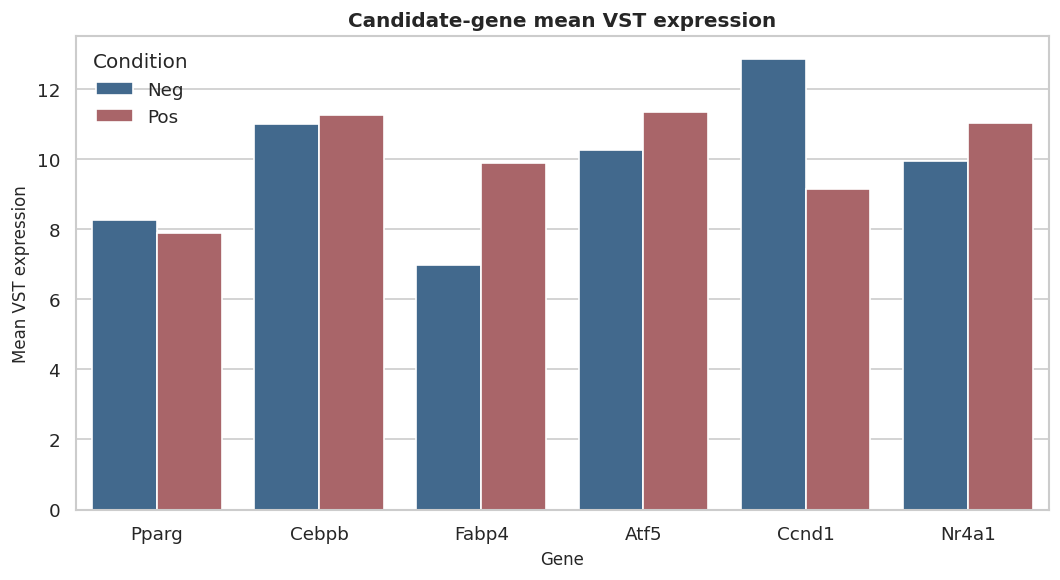

In [11]:
candidate_genes = ["PPARG", "CEBPB", "FABP4", "ATF5", "CCND1", "NR4A1"]
# Case-insensitive match while retaining matrix spelling.
candidate_mask = results["gene_symbol"].fillna("").str.casefold().isin([g.casefold() for g in candidate_genes])
candidate_rows = results.loc[candidate_mask, [GENE_COL, "gene_symbol", *SAMPLE_COLS, "Neg_mean", "Pos_mean", "difference", "p_value", "adjusted_p"]].copy()
display(candidate_rows.round(4))
if not candidate_rows.empty:
    candidate_rows["_rank_p"] = candidate_rows["adjusted_p"].fillna(np.inf)
    candidate_rows["_gene_key"] = candidate_rows["gene_symbol"].str.casefold()
    candidate_plot = candidate_rows.sort_values("_rank_p").drop_duplicates("_gene_key", keep="first")
    candidate_plot = candidate_plot.set_index(candidate_plot["gene_symbol"].str.upper()).reindex(candidate_genes).dropna(subset=["Neg_mean", "Pos_mean"])
    if not candidate_plot.empty:
        long = candidate_plot.reset_index(drop=True).melt(id_vars=["gene_symbol"], value_vars=["Neg_mean", "Pos_mean"], var_name="Condition", value_name="Mean VST expression")
        long["Condition"] = long["Condition"].map({"Neg_mean": "Neg", "Pos_mean": "Pos"})
        fig, ax = plt.subplots(figsize=(9, 5))
        sns.barplot(data=long, x="gene_symbol", y="Mean VST expression", hue="Condition", palette={"Neg":"#356a9a", "Pos":"#b45a5f"}, ax=ax)
        ax.set(title="Candidate-gene mean VST expression", xlabel="Gene", ylabel="Mean VST expression")
        ax.legend(title="Condition", frameon=False)
        fig.tight_layout(); plt.show()


## **12. Limitations and future directions**

1. **Small sample size:** three samples per condition provide limited power and unstable variance estimates.
2. **Processed input:** the available matrix contains VST expression values, not raw counts. A proper count-based model cannot be reconstructed from this matrix alone.
3. **Exploratory test:** Welch's t-test on VST values is not equivalent to DESeq2/edgeR and may not adequately model RNA-seq uncertainty.
4. **Duplicate symbols:** repeated labels can create multiple row-level tests and complicate symbol-based enrichment. The notebook preserves row-level results and documents display/ranking-specific deduplication.
5. **Gene-set resources:** enrichment depends on the available version of GO libraries, annotation coverage, and symbol mapping. External service failures are surfaced rather than replaced with stale results.
6. **Selected gene sets:** a focused analysis tests targeted hypotheses and should not be presented as a comprehensive unbiased pathway screen.
7. **No causal inference:** enrichment and expression associations do not demonstrate functional activation, suppression, or causal mechanisms.

**Future work:** Where available, obtain the original raw count data and sample metadata; confirm the experimental design and independence of biological replicates; perform count-based differential-expression analysis using an appropriate statistical model; use stable gene identifiers and documented annotation mapping; and evaluate key findings in an independent dataset. Candidate genes should be treated as hypotheses for further investigation rather than established regulators.


## **13. Integrated Results and Interpretation**

This exploratory reanalysis identified condition-associated gene-expression patterns between day-30 non-differentiating (Neg) and differentiating (Pos) mouse embryonic stem cell samples.

The row-level differential-expression screen identified **1,089 matrix rows with BH-adjusted p-values below 0.05**, comprising 344 rows with higher mean expression and 745 with lower mean expression in Pos relative to Neg. These are row-level results; duplicated gene symbols mean that the number of significant rows does not necessarily equal the number of unique genes.

Direction-specific Gene Ontology Biological Process enrichment identified **6 significant terms among genes higher in Pos and 97 among genes lower in Pos** in the current analysis. The enriched annotations included nervous-system-development-related terms among the higher-expression set and epithelial differentiation and structural-organization-related terms among the lower-expression set. These annotations describe statistical over-representation, not direct evidence that a biological process is activated or suppressed.

The selected gene-set analysis highlighted **extracellular matrix organization** (NES approximately 1.81) and **epithelial cell differentiation** (NES approximately −1.61; FDR approximately 0.0067). The positive and negative enrichment scores indicate opposite directions relative to the Pos-minus-Neg ranking. Lipid metabolism and adipose tissue development were not significantly enriched in the selected gene-set analysis.

Together, these results suggest that extracellular-matrix organization and epithelial-differentiation-associated expression patterns merit further investigation in this dataset. They do not establish causal mechanisms or confirm that the observed changes are specific to adipogenic differentiation.

**Interpretive limitations:** The analysis uses a processed variance-stabilized expression matrix and only three samples per condition. Welch's t-tests on VST values are exploratory and are not equivalent to count-based RNA-seq differential-expression modelling. Duplicate gene symbols, annotation coverage, and tied GSEA ranking statistics also limit fine-grained interpretation. The findings should therefore be treated as hypotheses for follow-up, ideally using the original raw counts, an appropriate count-based model, and independent validation.

## **14. References and data access**

1. Sultana et al. (2024). “Transcriptional Dynamics and Key Regulators of Adipogenesis in Mouse Embryonic Stem Cells: Insights from Robust Rank Aggregation Analysis.” *International Journal of Molecular Sciences*, 25(17), 9154. [Full text](https://pmc.ncbi.nlm.nih.gov/articles/PMC11395306/). [Supplementary material](https://www.mdpi.com/article/10.3390/ijms25179154/s1?download=1).
2. NCBI BioProject **PRJNA1126392**: https://www.ncbi.nlm.nih.gov/bioproject/PRJNA1126392
3. NCBI SRA study **SRP515101**: https://www.ncbi.nlm.nih.gov/sra/?term=SRP515101
4. Al-Sayegh lab bioinformatics repository: https://github.com/mxa1429/msc-bioinformatics-mohamed-alsayegh
5. Expression matrix: https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/refs/heads/main/Codes/vst_matrix_genes.csv
6. Benjamini, Y. & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.
7. Gene Ontology Consortium. [Gene Ontology resource](https://geneontology.org/).

The exact installed package versions and source path are printed in the setup section at runtime. The GO library name and retrieval date/version should be retained with exported results if this notebook is used for formal reporting.


## **15. Final reproducibility and validation checklist**

This checklist is evaluated at the end of a successful run. A successful notebook execution verifies code flow and output generation in the current environment; it does not establish that the study design or exploratory statistical assumptions are ideal.


In [12]:
_valid_p_check = results["p_value"].notna() & np.isfinite(results["p_value"])
_p_for_bh_check = results["p_value"].where(_valid_p_check, 1.0).to_numpy(dtype=float)
_bh_expected = multipletests(_p_for_bh_check, method="fdr_bh")[1]

_bh_matches = bool(np.allclose(
    results["adjusted_p"].to_numpy(dtype=float),
    _bh_expected,
    rtol=1e-10,
    atol=1e-12
))
validation = {
    "required_columns_present": all(c in df_raw.columns for c in required),
    "six_expected_samples_present": all(c in df.columns for c in SAMPLE_COLS),
    "numeric_expression_columns": all(pd.api.types.is_numeric_dtype(df[c]) for c in SAMPLE_COLS),
    "source_matrix_rows_retained": len(df) == len(df_raw),
    "contrast_defined_as_Pos_minus_Neg": bool((results["difference"] - (results["Pos_mean"] - results["Neg_mean"])).abs().dropna().max() < 1e-10),
    "BH_adjustment_matches_recalculation": _bh_matches,
    "PCA_has_six_sample_coordinates": len(meta) == 6,
    "results_table_matches_input_rows": len(results) == len(df),
    "GO_results_available": isinstance(go_results, dict) and any(isinstance(v, pd.DataFrame) and not v.empty for v in go_results.values()),
    "GSEA_results_available": isinstance(selected_gsea, pd.DataFrame) and not selected_gsea.empty,
    "input_is_VST_not_raw_counts": True,
}
validation_df = pd.DataFrame({"Check": list(validation.keys()), "Passed": list(validation.values())})
display(validation_df)
print(f"Validation checks passed: {sum(validation.values())}/{len(validation)}")
if not validation["GO_results_available"]:
    print("WARNING: GO enrichment results are unavailable in this run. Do not report GO findings from this run.")
if not validation["GSEA_results_available"]:
    print("WARNING: GSEA results are unavailable in this run. Do not report GSEA findings from this run.")
print("These checks validate workflow and output availability; they do not prove biological correctness. This notebook uses exploratory Welch tests on VST values, not a count-based DESeq2 model.")


,Check,Passed
0,required_columns_present,True
1,six_expected_samples_present,True
2,numeric_expression_columns,True
3,source_matrix_rows_retained,True
4,contrast_defined_as_Pos_minus_Neg,True
5,BH_adjustment_matches_recalculation,True
6,PCA_has_six_sample_coordinates,True
7,results_table_matches_input_rows,True
8,GO_results_available,True
9,GSEA_results_available,True


Validation checks passed: 11/11
These checks validate workflow and output availability; they do not prove biological correctness. This notebook uses exploratory Welch tests on VST values, not a count-based DESeq2 model.
